In [2]:
import pandas as pd
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules
import matplotlib.pyplot as plt
from funzioni_regole_di_associazione import genera_regole
from funzioni_regole_di_associazione import plot_metriche

In [3]:
df_vecchie = pd.read_csv(r'data/ra_dati2020.csv', encoding='utf-8', sep=';')
df_nuove = pd.read_csv(r'data/ra_dati2055_ssp126.csv', encoding='latin1', sep=';')
print(df_vecchie.shape)
print(df_nuove.shape)

(28, 715)
(28, 715)


In [4]:
soglie = [-4, 0, 10, 20, 30, 34]
etichette = ['freddo_estremo', 'molto_freddo', 'freddo', 'mite', 'caldo', 'molto_caldo', 'caldo_estremo']
supporto_min = 0.01
confidenza_min = 0.3

frequent_itemsets_2055_ssp126, regole_2055_ssp126 = genera_regole(soglie, etichette, supporto_min, confidenza_min, df_vecchie, df_nuove)

# Seleziono le metriche metriche ufficiali descritte nella documentazione di mlxtend
regole_2055_ssp126 = regole_2055_ssp126[['antecedents', 'consequents', 'antecedent support', 'consequent support', 
                                         'support', 'confidence', 'lift', 'leverage', 'conviction', 'zhangs_metric']]

# Limito le colonne numeriche a 6 decimali
numeriche = frequent_itemsets_2055_ssp126.select_dtypes(include='number').columns
frequent_itemsets_2055_ssp126[numeriche] = frequent_itemsets_2055_ssp126[numeriche].round(6)
numeriche = regole_2055_ssp126.select_dtypes(include='number').columns
regole_2055_ssp126[numeriche] = regole_2055_ssp126[numeriche].round(6)

# Salvo in CSV con punto come separatore decimale
frequent_itemsets_2055_ssp126.to_csv('output/frequent_itemsets_2055_ssp126.csv', index=False, sep=';', float_format='%.6f')
regole_2055_ssp126.to_csv('output/output_2055_ssp126.csv', index=False, sep=';', float_format='%.6f')

# Stampo
print(frequent_itemsets_2055_ssp126.shape)
print(frequent_itemsets_2055_ssp126.head())
print(regole_2055_ssp126.shape)
print(regole_2055_ssp126.head())

(208, 2)
    support                 itemsets
0  0.308587          (NEW_max_caldo)
1  0.083166  (NEW_max_caldo_estremo)
2  0.119884         (NEW_max_freddo)
3  0.347111           (NEW_max_mite)
4  0.141051    (NEW_max_molto_caldo)
(64, 10)
              antecedents              consequents  antecedent support  \
2         (OLD_max_caldo)          (NEW_max_caldo)            0.353832   
5          (OLD_min_mite)          (NEW_max_caldo)            0.395867   
12  (OLD_max_molto_caldo)  (NEW_max_caldo_estremo)            0.107043   
13        (OLD_min_caldo)  (NEW_max_caldo_estremo)            0.045245   
18       (OLD_max_freddo)         (NEW_max_freddo)            0.158206   

    consequent support   support  confidence      lift  leverage  conviction  \
2             0.308587  0.184189    0.520556  1.686898  0.075001    1.442112   
5             0.308587  0.182584    0.461227  1.494638  0.060425    1.283308   
12            0.083166  0.036116    0.337395  4.056875  0.027213    1.38368

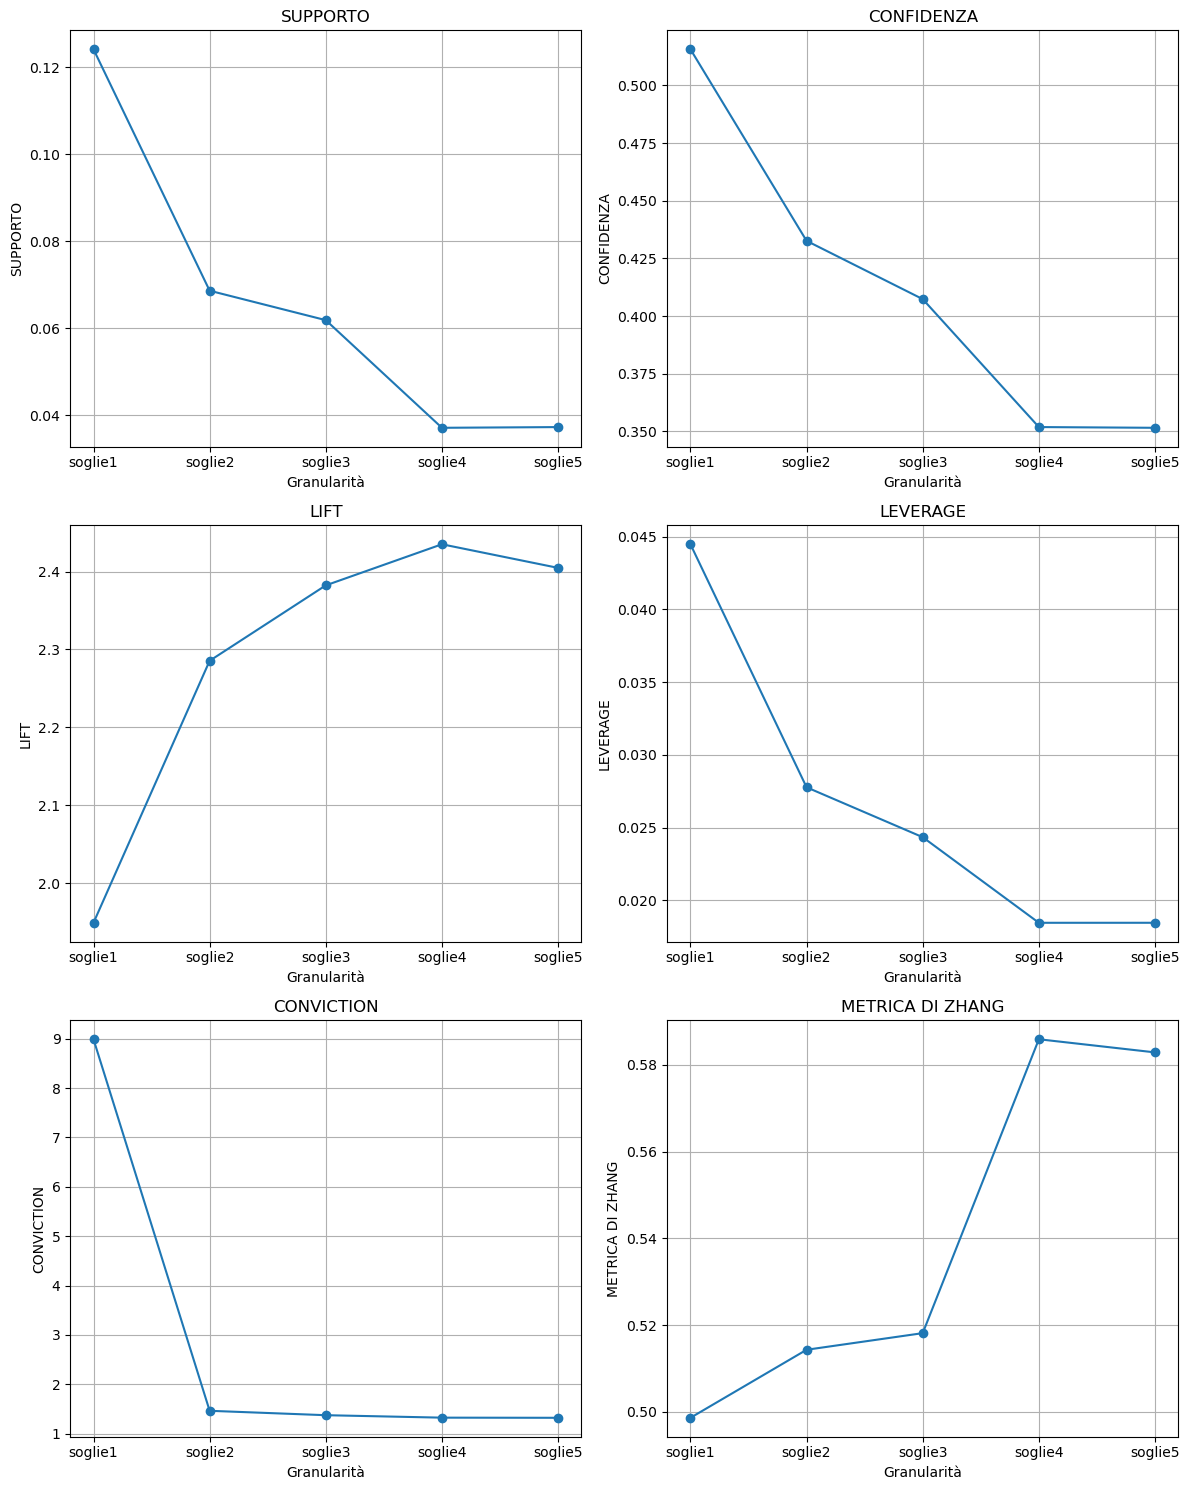

In [5]:
# ANALISI DELL'ANDAMENTO DELLE METRICHE AL VARIARE DELLA GRANULARITA'
# Definisco diversi livelli di soglia
soglie1 = [10, 20]
etichette1 = ['freddo', 'mite', 'caldo']

soglie2 = [0, 10, 20, 30]
etichette2 = ['molto_freddo', 'freddo', 'mite', 'caldo', 'molto_caldo']

soglie3 = [-4, 0, 10, 20, 30, 34]
etichette3 = ['freddo_estremo', 'molto_freddo', 'freddo', 'mite', 'caldo', 'molto_caldo', 'caldo_estremo']

soglie4 = [-4, 0, 10, 15, 20, 25, 30, 34]
etichette4 = [ 'freddo_estremo', 'molto_freddo', 'freddo', 'freddo_mite', 'mite', 'caldo_mite', 'caldo', 'molto_caldo', 
              'caldo_estremo']

soglie5 = [-8, -4, 0, 10, 15, 20, 25, 30, 34, 38]
etichette5 = ['freddo_eccezionale', 'freddo_estremo', 'molto_freddo', 'freddo', 'freddo_mite', 'mite', 'caldo_mite', 
              'caldo', 'molto_caldo', 'caldo_estremo', 'caldo_eccezionale']

# Definisco nuove soglie 
supporto_min = 0.0045
confidenza_min = 0.2

plot_metriche(soglie1, etichette1, soglie2, etichette2, soglie3, etichette3, soglie4, etichette4, soglie5, etichette5, supporto_min, confidenza_min, 
                  df_vecchie, df_nuove, "output/metriche_2055_ssp126.png")
